# Flight Delay Exploratory Data Analysis (EDA)

## Project Overview

This project explores flight delays using Python, Pandas, Matplotlib, Seaborn, and a public flight dataset.

The analysis investigates airline-level delays, airport-level patterns, scheduled departure times, extreme delays, and the relationship between departure and arrival delays.

### Objectives
- Understand the structure and quality of the dataset.
- Identify patterns in flight delays.
- Explore relationships between important variables.
- Communicate findings through visualizations and descriptive statistics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import urllib.request

url = "https://gist.githubusercontent.com/yinhao0424/4f81f1f1ac5907309772ae0181945b39/raw/1e5714cfbbf5f6caae5f7086a5cbd37b7fd8bd9c/flight.csv"

urllib.request.urlretrieve(url, "flight.csv")

df = pd.read_csv("flight.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7432, 31)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,4,11,6,WN,3777,N378SW,HOU,GSP,805,...,1107.0,-3.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,8,24,1,DL,1427,N951AT,ATL,SAV,2205,...,2303.0,-6.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,4,22,3,AS,2,N586AS,SEA,DCA,1355,...,2124.0,-33.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,3,28,6,VX,905,N528VA,LAS,SFO,1115,...,1233.0,-17.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,6,13,6,US,622,N586UW,PHX,JFK,1530,...,2307.0,-19.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Dataset Overview

The dataset contains flight records from 2015. Each record describes a flight and includes information about its airline, airports, scheduled and actual departure and arrival times, delays, distance, cancellations, and delay causes.

The initial dataset contains 7,432 rows and 31 columns. The analysis focuses on understanding data quality and identifying patterns in flight delays using descriptive statistics and visualizations.

## 2. Initial Data Inspection

Before performing exploratory analysis, we inspect the dataset's structure, column names, data types, and summary statistics. This helps us understand the available variables and identify potential data-quality issues.

In [3]:
# Dataset dimensions
print("Rows and columns:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Rows and columns: (7432, 31)

Column names:
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7432 entries, 0 to 7431
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 7432 non-null   int64  
 1   MONTH                7432 non-null   int64  
 2   DAY                  7432 non-null   int64  
 3   DAY_OF_WEEK          7432 non-null   int64  
 4   AIRLINE              7432 non-nul

In [4]:
df.describe()

,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,...,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
count,7432.0,7432.000000,7432.000000,7432.000000,7432.000000,7432.000000,7324.000000,7324.000000,7318.000000,7317.000000,...,7431.000000,7312.000000,7297.000000,7431.000000,7431.00000,1366.000000,1366.000000,1366.000000,1366.000000,1366.000000
mean,2015.0,6.541981,15.519376,3.930840,2182.924112,1333.699004,1335.895549,9.553113,16.122574,1358.442941,...,1495.044678,1479.737965,4.408935,0.002422,0.01561,13.644217,0.077599,19.725476,22.437042,2.467057
std,0.0,3.393434,8.724334,1.981697,1746.966949,481.366908,495.802695,37.334485,8.710341,497.550207,...,508.003905,526.870391,37.728368,0.049160,0.12397,27.785087,1.820473,44.335204,42.596274,14.340803
min,2015.0,1.000000,1.000000,1.000000,1.000000,15.000000,1.000000,-24.000000,1.000000,1.000000,...,1.000000,1.000000,-65.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.0,4.000000,8.000000,2.000000,744.750000,925.000000,921.000000,-5.000000,11.000000,936.000000,...,1110.000000,1059.000000,-13.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2015.0,7.000000,16.000000,4.000000,1706.000000,1330.000000,1332.000000,-1.000000,14.000000,1345.000000,...,1527.000000,1520.000000,-5.000000,0.000000,0.00000,1.000000,0.000000,2.000000,1.000000,0.000000
75%,2015.0,9.000000,23.000000,6.000000,3258.500000,1730.000000,1739.000000,7.000000,19.000000,1753.000000,...,1915.000000,1914.000000,8.000000,0.000000,0.00000,18.000000,0.000000,19.000000,28.000000,0.000000
max,2015.0,12.000000,31.000000,7.000000,7429.000000,2359.000000,2400.000000,1074.000000,116.000000,2359.000000,...,2359.000000,2400.000000,596.000000,1.000000,1.00000,331.000000,64.000000,574.000000,474.000000,201.000000


## 3. Data Quality Assessment

Data quality assessment helps identify missing values, duplicate records, and potentially invalid measurements before conducting further analysis.

Missing values are investigated according to their meaning rather than automatically removed or replaced.

In [5]:
missing_values = df.isnull().sum()

missing_summary = missing_values[missing_values > 0].sort_values(
    ascending=False
)

missing_summary

,0
CANCELLATION_REASON,7316
LATE_AIRCRAFT_DELAY,6066
AIRLINE_DELAY,6066
WEATHER_DELAY,6066
SECURITY_DELAY,6066
AIR_SYSTEM_DELAY,6066
ARRIVAL_DELAY,135
AIR_TIME,135
ELAPSED_TIME,135
WHEELS_ON,120


**Missing-Value Interpretation**

Missing values must be interpreted according to the meaning of each column. Missing cancellation reasons are expected for flights that were not cancelled. Missing delay-cause fields may reflect how the data was recorded or whether a delay cause was applicable.

Missing values are not automatically replaced or removed. The one record with a missing cancellation status remains unknown rather than being guessed.

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
print("Zero or negative distances:", (df["DISTANCE"] <= 0).sum())
print("Negative air times:", (df["AIR_TIME"] < 0).sum())
print("Negative taxi-out times:", (df["TAXI_OUT"] < 0).sum())
print("Negative taxi-in times:", (df["TAXI_IN"] < 0).sum())

Zero or negative distances: 0
Negative air times: 0
Negative taxi-out times: 0
Negative taxi-in times: 0


## 4. Exploratory Data Analysis

This section explores patterns in flight delays using descriptive statistics and visualizations. We investigate differences between airlines and airports, variation by scheduled departure time, extreme delays, and relationships between flight variables.

In [8]:
airline_stats = df.groupby("AIRLINE")["DEPARTURE_DELAY"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

airline_stats.round(2)

,count,mean,median
AIRLINE,,,
NK,164,19.24,0.0
UA,629,16.52,2.0
B6,346,12.86,-2.0
US,262,10.25,-2.0
WN,1562,10.09,0.0
F9,114,9.97,-3.0
EV,738,9.44,-3.0
VX,78,9.00,-2.0
MQ,358,8.29,-2.0


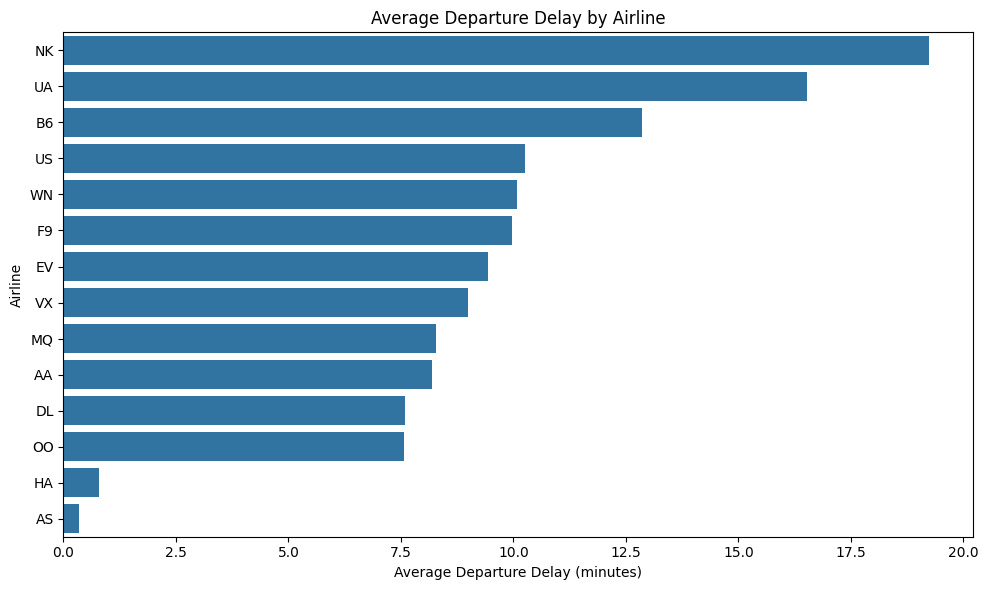

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=airline_stats.reset_index(),
    x="mean",
    y="AIRLINE"
)

plt.title("Average Departure Delay by Airline")
plt.xlabel("Average Departure Delay (minutes)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

### Interpretation

The average departure delay varies across airlines in this sample. Comparing the mean with the median helps identify cases where extreme delays may influence the average. Flight counts should also be considered before comparing airlines, because the number of observations differs between groups.

### 4.2 Additional Investigation: Mean vs Median Departure Delays

The mean can be influenced by extreme values, while the median represents the middle observation. Comparing these measures across airlines helps us investigate whether unusually large delays may be influencing average departure delays.

In [10]:
airline_comparison = (
    df.groupby("AIRLINE")["DEPARTURE_DELAY"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

airline_comparison.round(2)

,count,mean,median
AIRLINE,,,
NK,164,19.24,0.0
UA,629,16.52,2.0
B6,346,12.86,-2.0
US,262,10.25,-2.0
WN,1562,10.09,0.0
F9,114,9.97,-3.0
EV,738,9.44,-3.0
VX,78,9.00,-2.0
MQ,358,8.29,-2.0


### 4.3 Distribution of Departure Delays

This analysis examines the distribution of departure delays, including typical delays and unusually large delays. Mean, median, and percentile statistics help us understand the effect of extreme observations.

In [11]:
df["DEPARTURE_DELAY"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

,DEPARTURE_DELAY
count,7324.000000
mean,9.553113
std,37.334485
min,-24.000000
50%,-1.000000
75%,7.000000
90%,36.000000
95%,67.000000
99%,169.310000
max,1074.000000


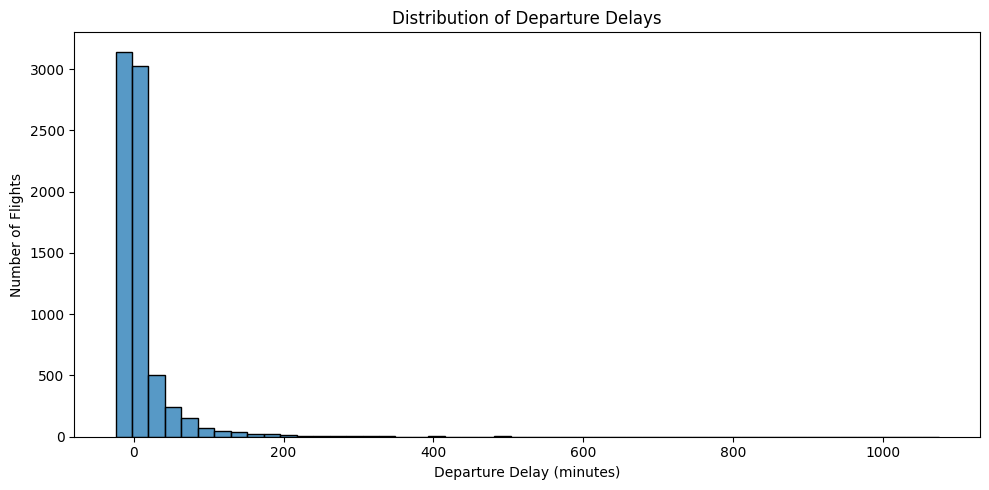

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="DEPARTURE_DELAY",
    bins=50
)

plt.title("Distribution of Departure Delays")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

In [13]:
delay = df["DEPARTURE_DELAY"]

print("Flights delayed over 60 minutes:", (delay > 60).sum())
print("Flights delayed over 120 minutes:", (delay > 120).sum())
print("Flights delayed over 180 minutes:", (delay > 180).sum())

Flights delayed over 60 minutes: 435
Flights delayed over 120 minutes: 147
Flights delayed over 180 minutes: 64


### Interpretation

Departure delays are right-skewed: a relatively small number of flights experience very large positive delays, increasing the mean above the median. Extreme observations are retained unless there is evidence that they are invalid.

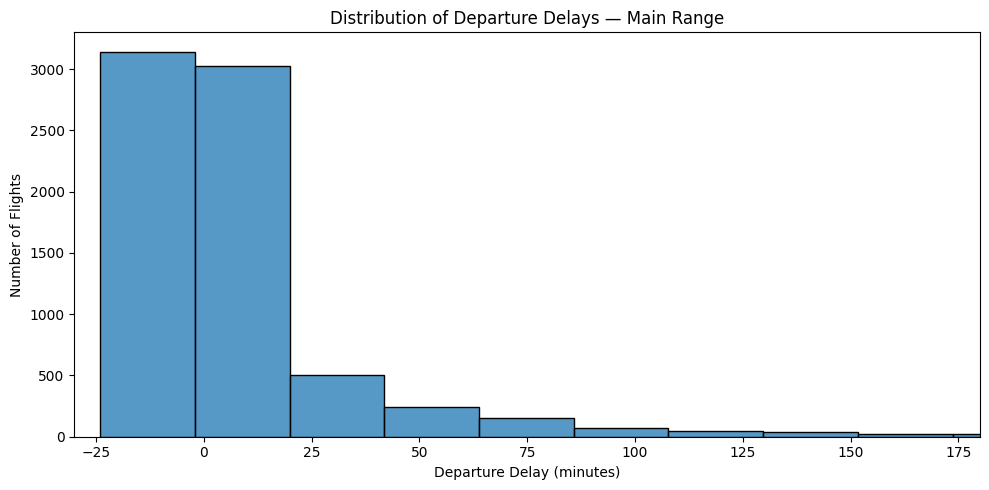

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="DEPARTURE_DELAY",
    bins=50
)

plt.xlim(-30, 180)
plt.title("Distribution of Departure Delays — Main Range")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

**Interpretation**

This zoomed-in view makes the distribution of most departure delays easier to examine. Observations outside the displayed range are excluded from the visualization only, not from the dataset or statistical calculations.

### 4.4 Departure Delays by Scheduled Departure Hour

This analysis explores how average departure delays vary throughout the day. The scheduled departure time is converted into an hour value, allowing us to compare delays across different hours.

To avoid drawing conclusions from hours with very few observations, only hours with at least 30 recorded departure delays are included in the comparison.

In [15]:
df["DEPARTURE_HOUR"] = (
    df["SCHEDULED_DEPARTURE"] // 100
).astype(int)

hourly_stats = (
    df.groupby("DEPARTURE_HOUR")["DEPARTURE_DELAY"]
    .agg(["count", "mean", "median"])
)

reliable_hours = hourly_stats[
    hourly_stats["count"] >= 30
]

reliable_hours.round(2)

,count,mean,median
DEPARTURE_HOUR,,,
5,152,-1.38,-3.0
6,499,-0.00,-3.0
7,490,2.78,-3.0
8,464,3.31,-3.0
9,471,4.67,-3.0
10,466,8.98,-2.0
11,448,6.78,-1.5
12,466,9.65,-1.0
13,428,10.47,-1.0


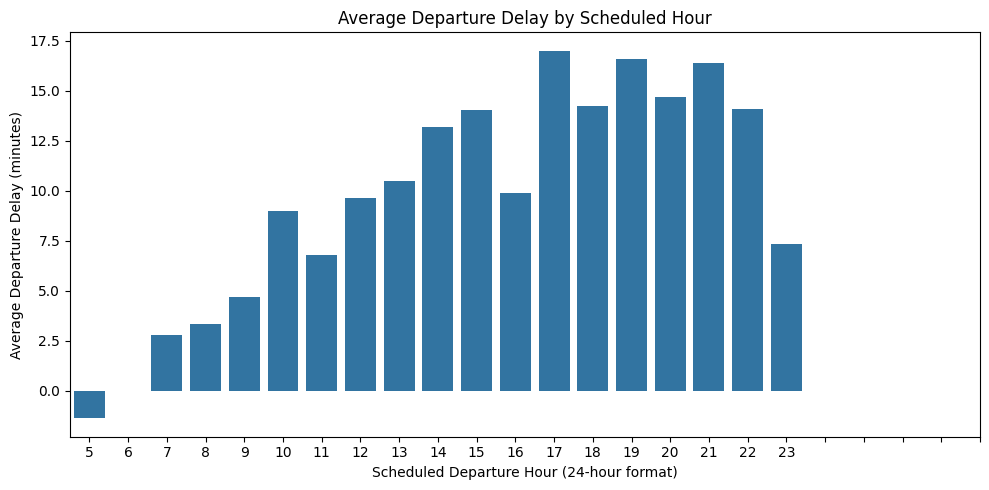

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=reliable_hours.index,
    y=reliable_hours["mean"]
)

plt.title("Average Departure Delay by Scheduled Hour")
plt.xlabel("Scheduled Departure Hour (24-hour format)")
plt.ylabel("Average Departure Delay (minutes)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

**Interpretation**

The average departure delay varies across scheduled departure hours. If later hours show higher average delays, this may indicate that delays become more common as the day progresses. However, this sample alone cannot establish the cause of the pattern. Hours with fewer observations are excluded to make the comparison more reliable.

### 4.5 Departure Delays by Origin Airport

This analysis compares average departure delays across origin airports. Airports with fewer observations may produce misleading averages, so only airports with at least 30 recorded departure delays are included. The ten airports with the highest average departure delays are then selected for comparison.

In [17]:
airport_stats = (
    df.groupby("ORIGIN_AIRPORT")["DEPARTURE_DELAY"]
    .agg(["count", "mean", "median"])
)

airport_stats = airport_stats[
    airport_stats["count"] >= 30
]

top_airports = (
    airport_stats
    .sort_values("mean", ascending=False)
    .head(10)
    .sort_values("mean")
)

top_airports.round(2)

,count,mean,median
ORIGIN_AIRPORT,,,
PHL,84,13.54,-2.0
SFO,198,14.42,-1.0
EWR,131,14.82,-1.0
MIA,97,15.19,-1.0
BWI,106,15.85,2.5
DAL,64,19.16,0.0
TPA,87,20.64,0.0
LGA,131,21.29,-3.0
RSW,37,21.84,-1.0


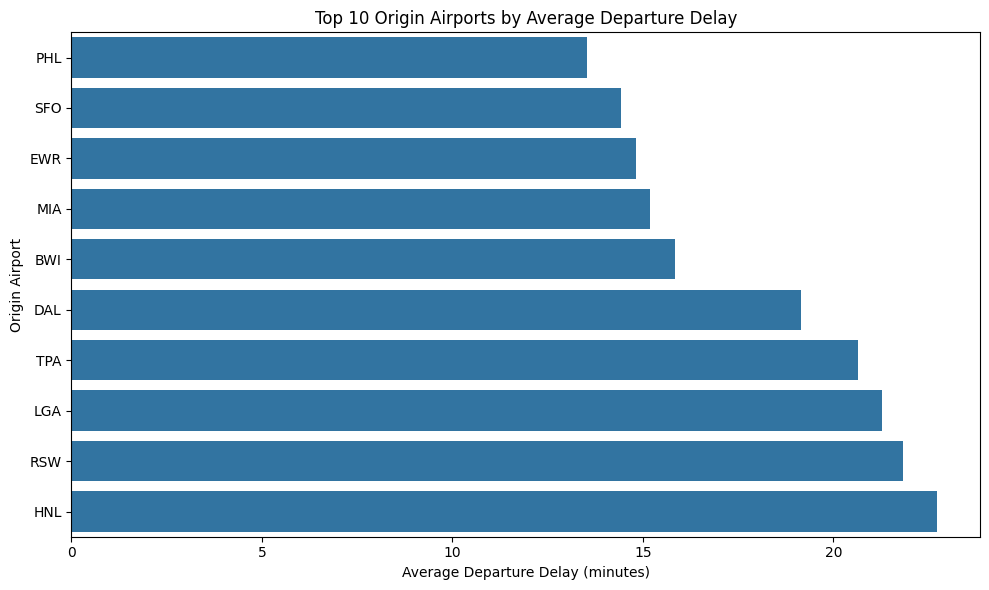

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_airports["mean"],
    y=top_airports.index
)

plt.title("Top 10 Origin Airports by Average Departure Delay")
plt.xlabel("Average Departure Delay (minutes)")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

**Interpretation**

The chart identifies the origin airports with the highest average departure delays in this dataset sample. Differences between airports may reflect various factors, but this analysis alone cannot determine their causes. The results should be interpreted alongside the number of observations for each airport and should not be treated as a ranking of overall airport performance.

### 4.6 Relationship Between Departure Delay and Arrival Delay

This analysis investigates the relationship between departure delays and arrival delays. It helps us understand whether flights that depart late also tend to arrive late. A correlation coefficient and scatter plot are used to examine the strength and direction of this relationship.

In [19]:
delay_corr = df[
    ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]
].corr()

delay_corr

,DEPARTURE_DELAY,ARRIVAL_DELAY
DEPARTURE_DELAY,1.000000,0.942551
ARRIVAL_DELAY,0.942551,1.000000


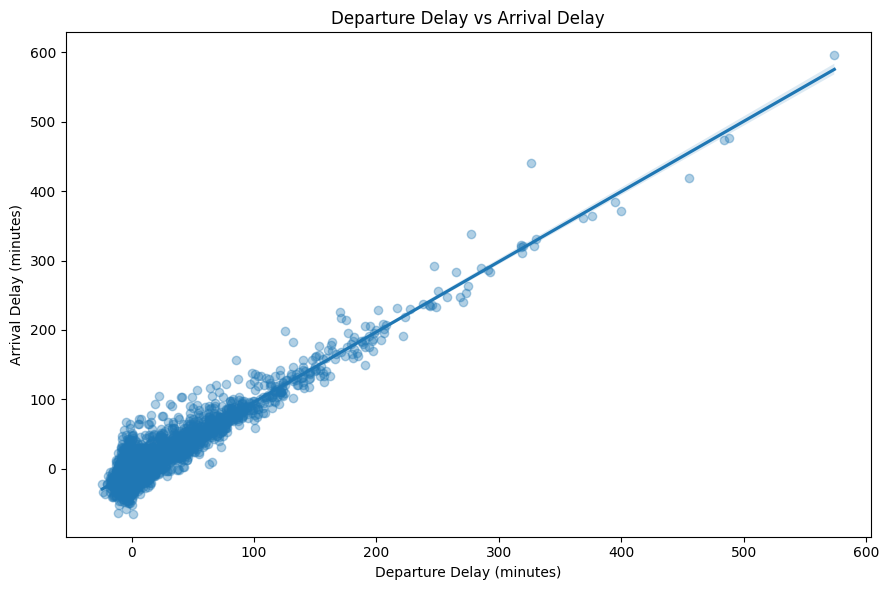

In [20]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="DEPARTURE_DELAY",
    y="ARRIVAL_DELAY",
    scatter_kws={"alpha": 0.35}
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")

plt.tight_layout()
plt.show()

**Interpretation**

The analysis shows a strong positive relationship between departure delays and arrival delays. Flights that depart late generally tend to arrive late as well. The correlation is close to 1, indicating a strong positive linear association. However, correlation does not prove causation, and some flights may reduce their delays before arrival.

### 4.7 Relationship Between Flight Distance and Arrival Delay

This analysis examines whether flight distance is associated with arrival delays. We use correlation analysis and a scatter plot to explore whether longer flights tend to experience greater or smaller arrival delays.

In [21]:
distance_corr = df[
    ["DISTANCE", "ARRIVAL_DELAY"]
].corr()

distance_corr

,DISTANCE,ARRIVAL_DELAY
DISTANCE,1.000000,-0.048184
ARRIVAL_DELAY,-0.048184,1.000000


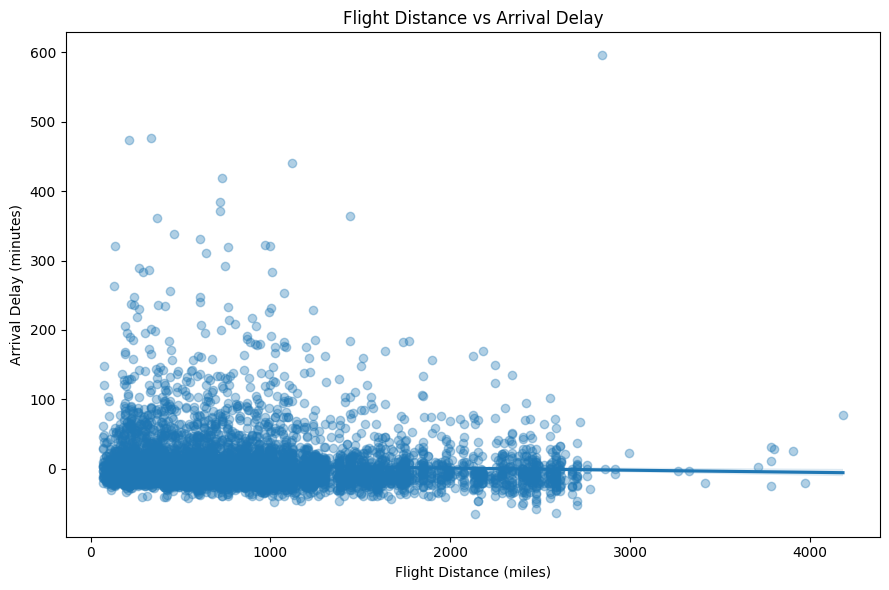

In [22]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="DISTANCE",
    y="ARRIVAL_DELAY",
    scatter_kws={"alpha": 0.35}
)

plt.title("Flight Distance vs Arrival Delay")
plt.xlabel("Flight Distance (miles)")
plt.ylabel("Arrival Delay (minutes)")

plt.tight_layout()
plt.show()

**Interpretation**

The correlation coefficient is close to zero, suggesting that flight distance has very little linear association with arrival delay in this sample. Longer flights do not necessarily experience greater or smaller arrival delays. Other factors may be more relevant, and this result does not rule out more complex relationships.

### 4.8 Difference Between Departure and Arrival Delays


This analysis investigates whether flights reduce their delays between departure and arrival. We calculate the difference between departure delay and arrival delay for flights with both values available.

A positive difference means the arrival delay is smaller than the departure delay, while a negative difference means the arrival delay is greater.

In [23]:
delay_data = df[
    ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]
].dropna().copy()

delay_data["DELAY_REDUCTION"] = (
    delay_data["DEPARTURE_DELAY"]
    - delay_data["ARRIVAL_DELAY"]
)

delay_data["DELAY_REDUCTION"].describe()

,DELAY_REDUCTION
count,7297.000000
mean,4.961765
std,12.610370
min,-114.000000
25%,-1.000000
50%,6.000000
75%,12.000000
max,66.000000


In [24]:
recovered = (delay_data["DELAY_REDUCTION"] > 0).sum()
unchanged = (delay_data["DELAY_REDUCTION"] == 0).sum()
increased = (delay_data["DELAY_REDUCTION"] < 0).sum()

total = len(delay_data)

print(f"Flights with reduced delays: {recovered} ({recovered / total * 100:.2f}%)")
print(f"Flights with unchanged delays: {unchanged} ({unchanged / total * 100:.2f}%)")
print(f"Flights with increased delays: {increased} ({increased / total * 100:.2f}%)")

Flights with reduced delays: 5144 (70.49%)
Flights with unchanged delays: 235 (3.22%)
Flights with increased delays: 1918 (26.28%)


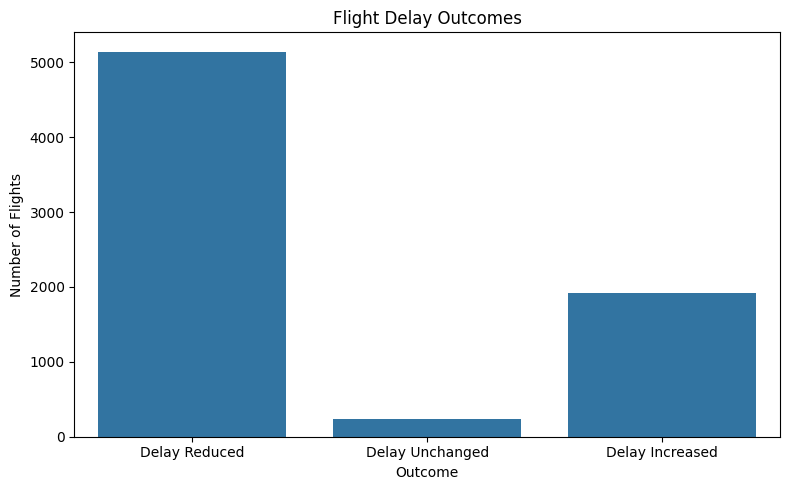

In [25]:
outcome_counts = pd.Series({
    "Delay Reduced": recovered,
    "Delay Unchanged": unchanged,
    "Delay Increased": increased
})

plt.figure(figsize=(8, 5))

sns.barplot(
    x=outcome_counts.index,
    y=outcome_counts.values
)

plt.title("Flight Delay Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

**Interpretation**

The analysis compares flights whose delays decreased, remained unchanged, or increased between departure and arrival. A reduced delay means the difference between the two recorded delays is positive. However, this measure does not necessarily represent time saved during flight, because scheduled flight duration and operational factors may also influence arrival delays.

## 5. Key Findings and Conclusion

### Key Findings

1. **Airline delays:** Average departure delays vary across airlines. Average and median delays should both be considered because extreme delays can influence the mean.
2. **Delay distribution:** Departure delays are right-skewed, with a relatively small number of flights experiencing very large delays.
3. **Time of departure:** Average departure delays vary across scheduled departure hours. Hours with fewer observations require cautious interpretation.
4. **Origin airports:** Some airports show higher average departure delays than others in this sample, although differences in sample size may affect the comparison.
5. **Departure and arrival delays:** A strong positive correlation indicates that flights departing late generally tend to arrive late.
6. **Flight distance:** The correlation between flight distance and arrival delay is close to zero, indicating little linear association in this sample.
7. **Delay recovery:** Comparing departure and arrival delays shows that some flights arrive with smaller delays than they had at departure, while others experience increased delays.

### Conclusion

This Exploratory Data Analysis (EDA) examined flight delays using Python, Pandas, Matplotlib, and Seaborn. The analysis explored data quality, delay distributions, airline and airport differences, scheduled departure hours, and relationships between flight characteristics and delays.

The findings demonstrate how data analysis and visualization can reveal patterns in operational data. However, the dataset represents a limited sample, so the findings should not be generalized to all flights or used to establish causal relationships.

Further analysis using a larger, clearly documented dataset could investigate seasonal trends, weather conditions, congestion, and other factors that may influence flight delays.

## 6. Limitations

- The dataset contains only a sample of flight records, so results may not represent the entire aviation industry.
- Missing values reduce the number of observations available for some analyses.
- Average delays can be influenced by extreme observations.
- Correlation does not establish causation.
- The analysis does not include external factors such as weather, air traffic congestion, or operational disruptions.
- The dataset is a sample obtained through a public GitHub Gist. Its row count differs from the count described in the Gist README, and the reason for this difference has not been established.

## 7. Dataset Source and Attribution

This project analyzes a sample of flight records downloaded from a public GitHub Gist.

- **Sample source:** [GitHub Gist](https://gist.github.com/yinhao0424/4f81f1f1ac5907309772ae0181945b39)
- **Direct CSV:** [flight.csv](https://gist.githubusercontent.com/yinhao0424/4f81f1f1ac5907309772ae0181945b39/raw/1e5714cfbbf5f6caae5f7086a5cbd37b7fd8bd9c/flight.csv)
- **Reported upstream source:** [2015 Flight Delays and Cancellations on Kaggle](https://www.kaggle.com/datasets/usdot/flight-delays)
- **Dataset scope:** 7,432 rows and 31 columns in the downloaded sample.

The Gist describes its dataset as originating from Kaggle, but the reason for the difference between its documented row count and the downloaded sample has not been established. The original Kaggle dataset is listed as CC0; the provenance and licensing of any separate contributions to this sample have not been independently verified.